In [2]:
!pip -q install tensorflow datasets pymupdf rouge-score nltk pandas matplotlib scikit-learn kagglehub

In [16]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from pathlib import Path
from collections import Counter
from datasets import load_dataset
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Libraries imported successfully!


In [17]:
DATASET_PATH = Path(
    kagglehub.dataset_download(
        "thedevastator/ccdv-arxiv-summarization-dataset"
    )
)

print("Dataset downloaded successfully!")
print("Dataset path:", DATASET_PATH)

for item in sorted(DATASET_PATH.rglob("*")):
    if item.is_file():
        print(item.relative_to(DATASET_PATH))


Using Colab cache for faster access to the 'ccdv-arxiv-summarization-dataset' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/ccdv-arxiv-summarization-dataset
test.csv
train.csv
validation.csv


In [18]:
import json

data_files = [
    file for file in DATASET_PATH.rglob("*")
    if file.is_file()
    and file.suffix.lower() in [".csv", ".json", ".jsonl", ".parquet"]
]

print("Number of data files:", len(data_files))

for i, file in enumerate(data_files, start=1):
    print(f"{i}. {file.relative_to(DATASET_PATH)}")

if not data_files:
    raise FileNotFoundError(
        "No CSV, JSON, JSONL, or Parquet files were found."
    )


Number of data files: 3
1. validation.csv
2. train.csv
3. test.csv


In [19]:
from pathlib import Path
import pandas as pd

print("Finding train.csv...", flush=True)

train_files = list(DATASET_PATH.rglob("train.csv"))

if not train_files:
    raise FileNotFoundError("train.csv was not found.")

train_path = train_files[0]

print("File found:", train_path, flush=True)
print("File size (MB):", round(train_path.stat().st_size / (1024**2), 2), flush=True)

print("Reading 5 rows...", flush=True)

df = pd.read_csv(train_path, nrows=5, low_memory=False)

print("Reading completed!", flush=True)
print("Columns:", df.columns.tolist())

display(df)


Finding train.csv...
File found: /kaggle/input/ccdv-arxiv-summarization-dataset/train.csv
File size (MB): 6868.13
Reading 5 rows...
Reading completed!
Columns: ['article', 'abstract']


,article,abstract
0,additive models @xcite provide an important fa...,additive models play an important role in semi...
1,the leptonic decays of a charged pseudoscalar ...,"we have studied the leptonic decay @xmath0 , v..."
2,the transport properties of nonlinear non - eq...,"in 84 , 258 ( 2000 ) , mateos conjectured that..."
3,studies of laser beams propagating through tur...,the effect of a random phase diffuser on fluct...
4,the so - called `` nucleon spin crisis '' rais...,with a special intention of clarifying the und...


In [20]:
import pandas as pd

N_SAMPLES = 2000

train_path = DATASET_PATH / "train.csv"

df = pd.read_csv(
    train_path,
    nrows=N_SAMPLES,
    usecols=["article", "abstract"]
)


df = df.dropna(subset=["article", "abstract"])

df["article"] = df["article"].astype(str).str.strip()
df["abstract"] = df["abstract"].astype(str).str.strip()

df = df[
    (df["article"].str.len() > 0) &
    (df["abstract"].str.len() > 0)
].reset_index(drop=True)

print("Loaded samples:", len(df))
print("Columns:", df.columns.tolist())

print("\nFirst article:")
print(df.loc[0, "article"][:500])

print("\nReference abstract:")
print(df.loc[0, "abstract"][:300])


Loaded samples: 2000
Columns: ['article', 'abstract']

First article:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . 
 it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models

Reference abstract:
additive models play an important role in semiparametric statistics . 
 this paper gives learning rates for regularized kernel based methods for additive models . 
 these learning rates compare favourably in particular in high dimensions to recent results on optimal learning rates for purely nonpara


Article length statistics:
count     2000.000000
mean      5893.546500
std       4359.776157
min          4.000000
25%       3089.750000
50%       4894.500000
75%       7444.250000
max      46122.000000
Name: article_words, dtype: float64

Abstract length statistics:
count     2000.000000
mean       283.386000
std        611.650768
min          7.000000
25%        114.000000
50%        166.000000
75%        237.000000
max      11609.000000
Name: abstract_words, dtype: float64


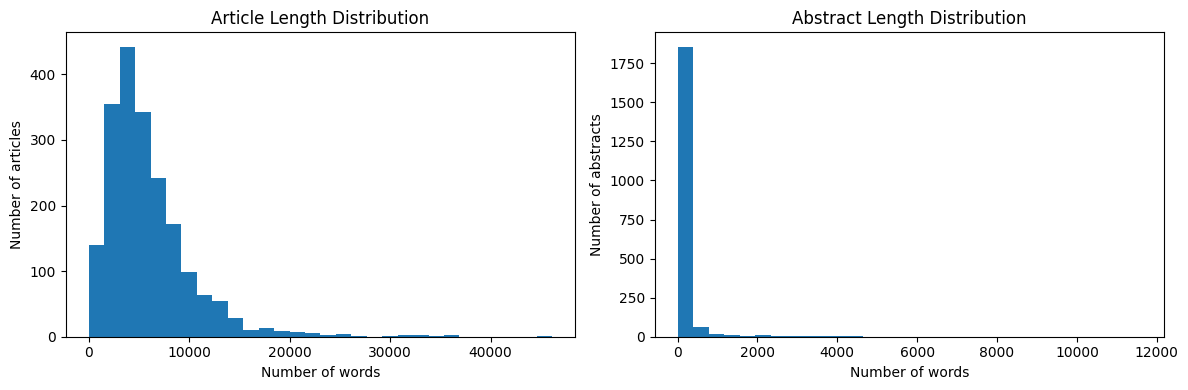

In [21]:

df["article_words"] = df["article"].str.split().str.len()
df["abstract_words"] = df["abstract"].str.split().str.len()

print("Article length statistics:")
print(df["article_words"].describe())

print("\nAbstract length statistics:")
print(df["abstract_words"].describe())


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df["article_words"], bins=30)
plt.title("Article Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of articles")

plt.subplot(1, 2, 2)
plt.hist(df["abstract_words"], bins=30)
plt.title("Abstract Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of abstracts")

plt.tight_layout()
plt.show()


In [22]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-z0-9.,;:!?()\- ]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

MAX_ARTICLE_WORDS = 600
MAX_ABSTRACT_WORDS = 120

def limit_words(text, max_words):
    words = text.split()
    return " ".join(words[:max_words])


df["article_clean"] = df["article"].apply(clean_text)
df["abstract_clean"] = df["abstract"].apply(clean_text)

df["article_input"] = df["article_clean"].apply(
    lambda text: limit_words(text, MAX_ARTICLE_WORDS)
)

df["abstract_target"] = df["abstract_clean"].apply(
    lambda text: limit_words(text, MAX_ABSTRACT_WORDS)
)


df = df[
    (df["article_input"].str.len() > 0) &
    (df["abstract_target"].str.len() > 0)
].reset_index(drop=True)

print("Number of usable samples:", len(df))

print("\nCleaned article:")
print(df.loc[0, "article_input"][:500])

print("\nTarget abstract:")
print(df.loc[0, "abstract_target"][:300])

Number of usable samples: 2000

Cleaned article:
additive models xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . 

Target abstract:
additive models play an important role in semiparametric statistics . this paper gives learning rates for regularized kernel based methods for additive models . these learning rates compare favourably in particular in high dimensions to recent results on optimal learning rates for purely nonparametr


In [23]:
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_ARTICLE_VOCAB = 30000
MAX_ABSTRACT_VOCAB = 15000

article_tokenizer = Tokenizer(
    num_words=MAX_ARTICLE_VOCAB,
    oov_token="<unk>"
)

abstract_tokenizer = Tokenizer(
    num_words=MAX_ABSTRACT_VOCAB,
    oov_token="<unk>",
    filters=""
)


article_tokenizer.fit_on_texts(df["article_input"])

decoder_texts = (
    "startseq " + df["abstract_target"] + " endseq"
).tolist()

abstract_tokenizer.fit_on_texts(decoder_texts)

print("Article vocabulary size:", len(article_tokenizer.word_index))
print("Abstract vocabulary size:", len(abstract_tokenizer.word_index))

print("\nExample word-to-number mapping:")
print(list(article_tokenizer.word_index.items())[:15])

Article vocabulary size: 30548
Abstract vocabulary size: 14263

Example word-to-number mapping:
[('<unk>', 1), ('the', 2), ('of', 3), ('in', 4), ('and', 5), ('a', 6), ('to', 7), ('is', 8), ('xcite', 9), ('for', 10), ('that', 11), ('with', 12), ('by', 13), ('are', 14), ('as', 15)]


In [24]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

article_sequences = article_tokenizer.texts_to_sequences(
    df["article_input"]
)

decoder_texts = [
    "startseq " + text + " endseq"
    for text in df["abstract_target"]
]

decoder_sequences = abstract_tokenizer.texts_to_sequences(
    decoder_texts
)


MAX_ENCODER_LEN = 600
MAX_DECODER_LEN = 122

encoder_input_data = pad_sequences(
    article_sequences,
    maxlen=MAX_ENCODER_LEN,
    padding="post",
    truncating="post"
)


decoder_input_data = pad_sequences(
    decoder_sequences,
    maxlen=MAX_DECODER_LEN,
    padding="post",
    truncating="post"
)

print("Encoder input shape:", encoder_input_data.shape)
print("Decoder input shape:", decoder_input_data.shape)

print("\nExample article sequence:")
print(encoder_input_data[0][:30])

print("\nExample decoder sequence:")
print(decoder_input_data[0][:30])

Encoder input shape: (2000, 600)
Decoder input shape: (2000, 122)

Example article sequence:
[ 4233    74     9   327    21   153  1261     3    74    10 18186  3663
    29  1539    84  1675    10     2  1971     3  4233    74    14    56
  1590  2793   123   608     7   229]

Example decoder sequence:
[  14 4005   77 1707   26  325  444    9 5845  547    4   24   82  929
 1108  634   13 3496 1357   60  251   13 4005   77    4   37 1108  634
  503 8021]


In [25]:
decoder_target_data = np.zeros_like(decoder_input_data)

decoder_target_data[:, :-1] = decoder_input_data[:, 1:]

print("Decoder input shape:", decoder_input_data.shape)
print("Decoder target shape:", decoder_target_data.shape)

print("\nFirst 20 decoder input tokens:")
print(decoder_input_data[0][:20])

print("\nFirst 20 decoder target tokens:")
print(decoder_target_data[0][:20])

Decoder input shape: (2000, 122)
Decoder target shape: (2000, 122)

First 20 decoder input tokens:
[  14 4005   77 1707   26  325  444    9 5845  547    4   24   82  929
 1108  634   13 3496 1357   60]

First 20 decoder target tokens:
[4005   77 1707   26  325  444    9 5845  547    4   24   82  929 1108
  634   13 3496 1357   60  251]


In [26]:
from sklearn.model_selection import train_test_split

(
    encoder_train,
    encoder_val,
    decoder_train,
    decoder_val,
    target_train,
    target_val
) = train_test_split(
    encoder_input_data,
    decoder_input_data,
    decoder_target_data,
    test_size=0.10,
    random_state=42
)

print("Training samples:", len(encoder_train))
print("Validation samples:", len(encoder_val))

print("\nEncoder training shape:", encoder_train.shape)
print("Decoder training shape:", decoder_train.shape)
print("Target training shape:", target_train.shape)

print("\nEncoder validation shape:", encoder_val.shape)
print("Decoder validation shape:", decoder_val.shape)
print("Target validation shape:", target_val.shape)

Training samples: 1800
Validation samples: 200

Encoder training shape: (1800, 600)
Decoder training shape: (1800, 122)
Target training shape: (1800, 122)

Encoder validation shape: (200, 600)
Decoder validation shape: (200, 122)
Target validation shape: (200, 122)


In [28]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Attention,
    Concatenate,
    Dropout,
    Lambda
)
from tensorflow.keras.models import Model

ARTICLE_VOCAB_SIZE = min(
    MAX_ARTICLE_VOCAB,
    len(article_tokenizer.word_index) + 1
)

ABSTRACT_VOCAB_SIZE = min(
    MAX_ABSTRACT_VOCAB,
    len(abstract_tokenizer.word_index) + 1
)

EMBEDDING_DIM = 128
LATENT_DIM = 256


encoder_inputs = Input(
    shape=(MAX_ENCODER_LEN,),
    dtype="int32",
    name="encoder_inputs"
)

encoder_embedding_layer = Embedding(
    input_dim=ARTICLE_VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="article_embedding"
)

encoder_embedding = encoder_embedding_layer(encoder_inputs)

encoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    return_state=True,
    dropout=0.2,
    name="encoder_lstm"
)

encoder_outputs, encoder_state_h, encoder_state_c = encoder_lstm(
    encoder_embedding
)

encoder_mask_layer = Lambda(
    lambda x: tf.not_equal(x, 0),
    name="encoder_mask"
)

encoder_mask = encoder_mask_layer(encoder_inputs)


decoder_inputs = Input(
    shape=(MAX_DECODER_LEN,),
    dtype="int32",
    name="decoder_inputs"
)

decoder_embedding_layer = Embedding(
    input_dim=ABSTRACT_VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="abstract_embedding"
)

decoder_embedding = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    return_state=True,
    dropout=0.2,
    name="decoder_lstm"
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding,
    initial_state=[encoder_state_h, encoder_state_c]
)

decoder_mask_layer = Lambda(
    lambda x: tf.not_equal(x, 0),
    name="decoder_mask"
)

decoder_mask = decoder_mask_layer(decoder_inputs)


attention_layer = Attention(name="attention")

attention_context = attention_layer(
    [decoder_outputs, encoder_outputs],
    mask=[decoder_mask, encoder_mask]
)


combined_outputs = Concatenate(
    axis=-1,
    name="attention_concatenation"
)([decoder_outputs, attention_context])

combined_outputs = Dropout(
    0.2,
    name="output_dropout"
)(combined_outputs)


output_layer = Dense(
    ABSTRACT_VOCAB_SIZE,
    activation="softmax",
    name="word_prediction"
)

decoder_predictions = output_layer(combined_outputs)



model = Model(
    inputs=[encoder_inputs, decoder_inputs],
    outputs=decoder_predictions,
    name="scientific_summarizer"
)

print("Encoder-Decoder model with Attention created successfully.")
print("Article vocabulary size:", ARTICLE_VOCAB_SIZE)
print("Abstract vocabulary size:", ABSTRACT_VOCAB_SIZE)

model.summary()


Encoder-Decoder model with Attention created successfully.
Article vocabulary size: 30000
Abstract vocabulary size: 14264


Model: "scientific_summarizer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 600)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 122)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ article_embedding   │ (None, 600, 128)  │  3,840,000 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_6         │ (None, 600)       │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ abstract_embedding  │ (None, 122, 128)  │  1,825,792 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 600,      │    394,240 │ article_embeddin… │
│                     │ 256), (None,      │            │ not_equal_6[0][0] │
│                     │ 256), (None,      │            │                   │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 122,      │    394,240 │ abstract_embeddi… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_mask        │ (None, 122)       │          0 │ decoder_inputs[0… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_mask        │ (None, 600)       │          0 │ encoder_inputs[0… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 122, 256)  │          0 │ decoder_lstm[0][… │
│ (Attention)         │                   │            │ encoder_lstm[0][… │
│                     │                   │            │ decoder_mask[0][… │
│                     │                   │            │ encoder_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_concaten… │ (None, 122, 512)  │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_dropout      │ (None, 122, 512)  │          0 │ attention_concat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_prediction     │ (None, 122,       │  7,317,432 │ output_dropout[0… │
│ (Dense)             │ 14264)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 13,771,704 (52.53 MB)

 Trainable params: 13,771,704 (52.53 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
import tensorflow as tf

def masked_sparse_categorical_crossentropy(y_true, y_pred):

    y_true = tf.cast(y_true, tf.int32)

    loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred
    )


    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)

    loss = loss * mask

    return tf.reduce_sum(loss) / (
        tf.reduce_sum(mask) + tf.keras.backend.epsilon()
    )


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=masked_sparse_categorical_crossentropy
)

print("Model compiled successfully.")
print("Padding tokens will not contribute to the loss.")

Model compiled successfully.
Padding tokens will not contribute to the loss.


In [30]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

BATCH_SIZE = 16
EPOCHS = 15

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_summarizer.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

model.optimizer.learning_rate.assign(0.001)

history = model.fit(
    [encoder_train, decoder_train],
    target_train,
    validation_data=(
        [encoder_val, decoder_val],
        target_val
    ),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[
        reduce_lr,
        early_stopping,
        checkpoint
    ],
    verbose=1
)

Epoch 1/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 7.7210
Epoch 1: val_loss improved from None to 6.64693, saving model to best_summarizer.keras

Epoch 1: finished saving model to best_summarizer.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 18s 94ms/step - loss: 7.0849 - val_loss: 6.6469 - learning_rate: 0.0010
Epoch 2/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 6.5165
Epoch 2: val_loss improved from 6.64693 to 6.38160, saving model to best_summarizer.keras

Epoch 2: finished saving model to best_summarizer.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - loss: 6.4399 - val_loss: 6.3816 - learning_rate: 0.0010
Epoch 3/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 6.2079
Epoch 3: val_loss improved from 6.38160 to 6.21882, saving model to best_summarizer.keras

Epoch 3: finished saving model to best_summarizer.keras
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - loss: 6.1471 - val_loss: 6.2188 - learning_rate: 0.0010
Epoch 4/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - 

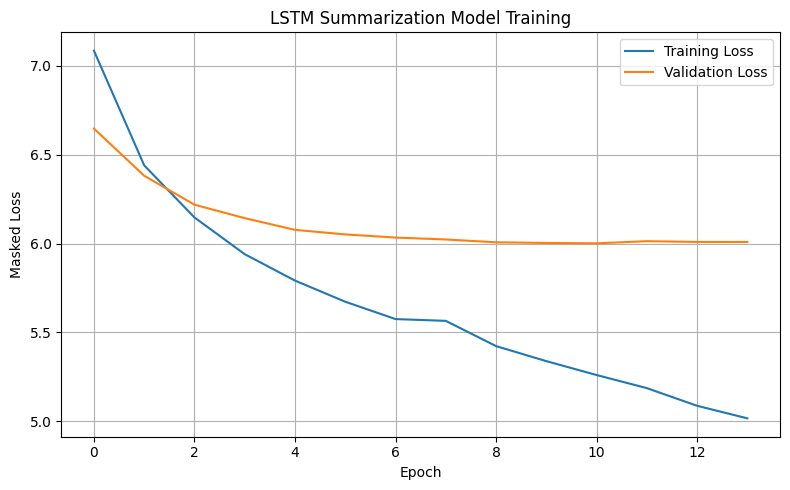

In [31]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Summarization Model Training")
plt.xlabel("Epoch")
plt.ylabel("Masked Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Concatenate
from tensorflow.keras.models import Model


encoder_inference_model = Model(
    inputs=encoder_inputs,
    outputs=[
        encoder_outputs,
        encoder_state_h,
        encoder_state_c
    ],
    name="encoder_inference_model"
)


inference_encoder_outputs = Input(
    shape=(MAX_ENCODER_LEN, LATENT_DIM),
    name="inference_encoder_outputs"
)

inference_state_h = Input(
    shape=(LATENT_DIM,),
    name="inference_state_h"
)

inference_state_c = Input(
    shape=(LATENT_DIM,),
    name="inference_state_c"
)

inference_token = Input(
    shape=(1,),
    dtype="int32",
    name="inference_token"
)


inference_embedding = decoder_embedding_layer(inference_token)

inference_decoder_outputs, next_state_h, next_state_c = decoder_lstm(
    inference_embedding,
    initial_state=[
        inference_state_h,
        inference_state_c
    ]
)


inference_context = attention_layer([
    inference_decoder_outputs,
    inference_encoder_outputs
])

inference_combined = Concatenate(axis=-1)([
    inference_decoder_outputs,
    inference_context
])

inference_predictions = output_layer(inference_combined)



decoder_inference_model = Model(
    inputs=[
        inference_token,
        inference_encoder_outputs,
        inference_state_h,
        inference_state_c
    ],
    outputs=[
        inference_predictions,
        next_state_h,
        next_state_c
    ],
    name="decoder_inference_model"
)

print("Encoder inference model created.")
print("Decoder inference model created.")

print("\nEncoder output shapes:")
for output in encoder_inference_model.outputs:
    print(output.shape)

print("\nDecoder output shapes:")
for output in decoder_inference_model.outputs:
    print(output.shape)

Encoder inference model created.
Decoder inference model created.

Encoder output shapes:
(None, 600, 256)
(None, 256)
(None, 256)

Decoder output shapes:
(None, 1, 14264)
(None, 256)
(None, 256)


In [33]:

import re
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.preprocessing.sequence import pad_sequences


def split_sentences(text):
    sentences = re.split(r"(?<=[.!?])\s+", text.strip())

    return [
        sentence.strip()
        for sentence in sentences
        if len(sentence.split()) >= 5
    ]



def select_important_sentences(text, top_k=8):
    sentences = split_sentences(text)

    if not sentences:
        return text[:3000]

    if len(sentences) <= top_k:
        return " ".join(sentences)

    try:
        vectorizer = TfidfVectorizer(
            stop_words="english",
            max_features=10000
        )

        sentence_vectors = vectorizer.fit_transform(sentences)
        document_vector = vectorizer.transform([text])

        scores = cosine_similarity(
            sentence_vectors,
            document_vector
        ).flatten()

        selected_indices = np.argsort(scores)[-top_k:]
        selected_indices = sorted(selected_indices)

        return " ".join(
            sentences[index] for index in selected_indices
        )

    except ValueError:
        return " ".join(sentences[:top_k])



def generate_abstractive_summary(text, max_words=100):

    cleaned_text = clean_text(text)

    cleaned_text = limit_words(
        cleaned_text,
        MAX_ENCODER_LEN
    )

    sequence = article_tokenizer.texts_to_sequences(
        [cleaned_text]
    )

    encoder_sequence = pad_sequences(
        sequence,
        maxlen=MAX_ENCODER_LEN,
        padding="post",
        truncating="post"
    )


    encoder_out, state_h, state_c = (
        encoder_inference_model.predict(
            encoder_sequence,
            verbose=0
        )
    )

    start_id = abstract_tokenizer.word_index.get("startseq")
    end_id = abstract_tokenizer.word_index.get("endseq")

    if start_id is None or end_id is None:
        raise ValueError(
            "Start/end tokens are missing from the abstract tokenizer."
        )

    current_token = np.array(
        [[start_id]],
        dtype=np.int32
    )

    generated_words = []

    for _ in range(max_words):

        predictions, state_h, state_c = (
            decoder_inference_model.predict(
                [
                    current_token,
                    encoder_out,
                    state_h,
                    state_c
                ],
                verbose=0
            )
        )


        next_id = int(
            np.argmax(predictions[0, -1, :])
        )

        if next_id == 0 or next_id == end_id:
            break

        word = abstract_tokenizer.index_word.get(
            next_id,
            "<unk>"
        )

        if word != "startseq":
            generated_words.append(word)

        current_token = np.array(
            [[next_id]],
            dtype=np.int32
        )

    return " ".join(generated_words).strip()



def hybrid_summarize(text, top_k=8, max_words=100):

    selected_text = select_important_sentences(
        text,
        top_k=top_k
    )

    generated_summary = generate_abstractive_summary(
        selected_text,
        max_words=max_words
    )

    return {
        "selected_sentences": selected_text,
        "summary": generated_summary
    }


print("Hybrid summarization pipeline is ready.")

Hybrid summarization pipeline is ready.


In [34]:
sample_article = df.loc[0, "article"]


result = hybrid_summarize(
    sample_article,
    top_k=8,
    max_words=100
)

print("=" * 80)
print("ORIGINAL ARTICLE (first 1000 characters)")
print("=" * 80)
print(sample_article[:1000])

print("\n" + "=" * 80)
print("EXTRACTED IMPORTANT SENTENCES")
print("=" * 80)
print(result["selected_sentences"])

print("\n" + "=" * 80)
print("GENERATED ABSTRACTIVE SUMMARY")
print("=" * 80)
print(result["summary"])

ORIGINAL ARTICLE (first 1000 characters)
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . 
 it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . 
 many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years 
 many interesting results on learning rates of regularized kernel based models for additive models have been published when the focus is on sparsity and when the classical least squares loss function is used , see e.g. @xcite , @xcite , @xcite , @xcite , @xcite , @xcite a

In [35]:
import re

def extract_scientific_sections(text):
    section_patterns = {
        "Abstract": [
            r"abstract",
        ],
        "Introduction": [
            r"introduction",
            r"background",
        ],
        "Methodology": [
            r"methodology",
            r"methods",
            r"materials\s+and\s+methods",
            r"proposed\s+method",
            r"approach",
            r"system\s+model",
            r"problem\s+formulation",
        ],
        "Results": [
            r"results",
            r"experimental\s+results",
            r"experiments",
            r"evaluation",
            r"simulation\s+results",
        ],
        "Discussion": [
            r"discussion",
        ],
        "Conclusion": [
            r"conclusion",
            r"conclusions",
            r"concluding\s+remarks",
        ],
        "Limitations": [
            r"limitations",
            r"future\s+work",
            r"conclusions?\s+and\s+future\s+work",
        ],
    }

    # Match headings at the beginning of a line, allowing section numbers.
    heading_regex = re.compile(
        r"(?im)^[ \t]*"
        r"(?:(?:\d+(?:\.\d+)*|[IVXLC]+)[.)]?[ \t]+)?"
        r"(?P<title>abstract|introduction|background|"
        r"methodology|methods|materials\s+and\s+methods|"
        r"proposed\s+method|approach|system\s+model|"
        r"problem\s+formulation|results|experimental\s+results|"
        r"experiments|evaluation|simulation\s+results|"
        r"discussion|conclusion|conclusions|concluding\s+remarks|"
        r"limitations|future\s+work|conclusions?\s+and\s+future\s+work)"
        r"[ \t]*[:.]?[ \t]*$"
    )

    matches = list(heading_regex.finditer(text))
    sections = {}

    def normalize_heading(heading):
        heading = re.sub(r"\s+", " ", heading.lower()).strip()

        for category, patterns in section_patterns.items():
            if any(re.fullmatch(pattern, heading) for pattern in patterns):
                return category

        if heading.startswith("conclusion"):
            return "Conclusion"

        return None

    for i, match in enumerate(matches):
        heading = match.group("title")
        category = normalize_heading(heading)

        if category is None:
            continue

        start = match.end()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        content = text[start:end].strip()

        if content:
            if category in sections:
                sections[category] += "\n\n" + content
            else:
                sections[category] = content

    return sections


pdf_sections = extract_scientific_sections(pdf_text)

print("Detected sections:", list(pdf_sections.keys()))

for section_name in [
    "Abstract",
    "Introduction",
    "Methodology",
    "Results",
    "Discussion",
    "Conclusion",
    "Limitations"
]:
    print("\n" + "=" * 70)
    print(section_name.upper())
    print("=" * 70)

    content = pdf_sections.get(section_name)

    if content:
        print(content[:2000])
    else:
        print("Section not detected.")


import re

def extract_scientific_sections(text):
    section_patterns = {
        "Abstract": [
            r"abstract",
        ],
        "Introduction": [
            r"introduction",
            r"background",
        ],
        "Methodology": [
            r"methodology",
            r"methods",
            r"materials\s+and\s+methods",
            r"proposed\s+method",
            r"approach",
            r"system\s+model",
            r"problem\s+formulation",
        ],
        "Results": [
            r"results",
            r"experimental\s+results",
            r"experiments",
            r"evaluation",
            r"simulation\s+results",
        ],
        "Discussion": [
            r"discussion",
        ],
        "Conclusion": [
            r"conclusion",
            r"conclusions",
            r"concluding\s+remarks",
        ],
        "Limitations": [
            r"limitations",
            r"future\s+work",
            r"conclusions?\s+and\s+future\s+work",
        ],
    }

    heading_regex = re.compile(
        r"(?im)^[ \t]*"
        r"(?:(?:\d+(?:\.\d+)*|[IVXLC]+)[.)]?[ \t]+)?"
        r"(?P<title>abstract|introduction|background|"
        r"methodology|methods|materials\s+and\s+methods|"
        r"proposed\s+method|approach|system\s+model|"
        r"problem\s+formulation|results|experimental\s+results|"
        r"experiments|evaluation|simulation\s+results|"
        r"discussion|conclusion|conclusions|concluding\s+remarks|"
        r"limitations|future\s+work|conclusions?\s+and\s+future\s+work)"
        r"[ \t]*[:.]?[ \t]*$"
    )

    matches = list(heading_regex.finditer(text))
    sections = {}

    def normalize_heading(heading):
        heading = re.sub(r"\s+", " ", heading.lower()).strip()

        for category, patterns in section_patterns.items():
            if any(re.fullmatch(pattern, heading) for pattern in patterns):
                return category

        if heading.startswith("conclusion"):
            return "Conclusion"

        return None

    for i, match in enumerate(matches):
        heading = match.group("title")
        category = normalize_heading(heading)

        if category is None:
            continue

        start = match.end()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        content = text[start:end].strip()

        if content:
            if category in sections:
                sections[category] += "\n\n" + content
            else:
                sections[category] = content

    return sections


pdf_sections = extract_scientific_sections(pdf_text)

print("Detected sections:", list(pdf_sections.keys()))

for section_name in [
    "Abstract",
    "Introduction",
    "Methodology",
    "Results",
    "Discussion",
    "Conclusion",
    "Limitations"
]:
    print("\n" + "=" * 70)
    print(section_name.upper())
    print("=" * 70)

    content = pdf_sections.get(section_name)

    if content:
        print(content[:2000])
    else:
        print("Section not detected.")


Detected sections: ['Introduction', 'Limitations']

ABSTRACT
Section not detected.

INTRODUCTION
A marsupial multi-robot conﬁguration [1] consists of a
system in which one robot carries and can deploy one or several other robots. One example is the conﬁguration in which
an Unmanned Ground Vehicle (UGV) carries an Unmanned
Aerial Vehicle (UAV), which can take off and possibly land
back on the UGV when needed. This conﬁguration can be
used to combine the strengths of UGVs and UAVs. This
UGV-UAV marsupial conﬁguration was used by the Team
CSIRO Data61 [2], reaching second place in the DARPA
2021 Subterranean Challenge [3]. Another notable example
is the Mars 2020 rover and helicopter [4]. The helicopter
augments the capabilities of the rover, exploring large areas
faster than the rover, providing reconnaissance on target
locations and safe to traverse routes.
The ﬂight time of small UAVs (few tens of minutes) is
one of its main limiting factors. To increase their endurance,
tethered UAVs 

In [36]:


import re
import fitz
from google.colab import files



print("Upload a scientific PDF file.")
uploaded = files.upload()

pdf_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".pdf")
]

if not pdf_files:
    raise ValueError("No PDF file was uploaded. Please upload a PDF.")

pdf_path = pdf_files[0]


document = fitz.open(pdf_path)

page_texts = []
for page_number, page in enumerate(document):
    page_text = page.get_text("text")
    if page_text.strip():
        page_texts.append(page_text)

pdf_text = "\n".join(page_texts)
document.close()

if len(pdf_text.strip()) < 100:
    raise ValueError(
        "Very little text was extracted. "
        "This PDF may be scanned and require OCR."
    )

print("\nPDF uploaded successfully.")
print("Pages with extracted text:", len(page_texts))
print("Extracted characters:", len(pdf_text))

pdf_text = re.sub(r"-\s*\n\s*", "", pdf_text)
pdf_text = re.sub(r"\n+", "\n", pdf_text)
pdf_text = re.sub(r"[ \t]+", " ", pdf_text)
pdf_text = pdf_text.strip()

print("\nGenerating summary...")

pdf_result = hybrid_summarize(
    pdf_text,
    top_k=8,
    max_words=100
)

print("\n" + "=" * 80)
print("HYBRID ABSTRACTIVE SUMMARY")
print("=" * 80)

if pdf_result["summary"]:
    print(pdf_result["summary"])
else:
    print("The model did not generate a summary. Check the model and vocabulary.")

print("\n" + "=" * 80)
print("EXTRACTED IMPORTANT SENTENCES")
print("=" * 80)
print(pdf_result["selected_sentences"])


pdf_sections = extract_scientific_sections(pdf_text)

for section_name in [
    "Abstract",
    "Introduction",
    "Methodology",
    "Results",
    "Discussion",
    "Conclusion",
    "Limitations"
]:
    print("\n" + "=" * 80)
    print(section_name.upper())
    print("=" * 80)

    content = pdf_sections.get(section_name)

    if content:
        print(content[:2500])
    else:
        print("Section not detected in the extracted PDF text.")



print("\n" + "=" * 80)
print("PDF PROCESSING COMPLETED")
print("=" * 80)
print("File:", pdf_path)
print("Pages:", len(page_texts))
print("Extracted text length:", len(pdf_text), "characters")

Upload a scientific PDF file.


Saving Path and trajectory planning of a tethered UAV-UGV marsupial robotic.pdf to Path and trajectory planning of a tethered UAV-UGV marsupial robotic (2).pdf

PDF uploaded successfully.
Pages with extracted text: 8
Extracted characters: 43596

Generating summary...

HYBRID ABSTRACTIVE SUMMARY
we present the first - dimensional model of the xmath0 of the xmath0 of the xmath0 of the xmath0 of the xmath0 . we show that the first - dimensional model is a large - dimensional model of the two - dimensional model . we show that the results of the two - dimensional model is a large - scale model . we show that the results of the two - dimensional model is a large - scale model . we show that the results is a large - scale model . we show that the results is a large

EXTRACTED IMPORTANT SENTENCES
Path and trajectory planning of a tethered UAV-UGV marsupial robotic
system*
S. The main contributions of the letter are:
• A path planning method based on RRT* that generates
collision-free paths fo